# Benchmark: computational scaling with electrode count

We keep single ion, its initial position, the RF drive, the original DC voltage distribution, the physical trap footprint, and the numerical simulation setup fixed while subdividing each of the three original DC electrodes on each side into multiple adjacent, same-voltage rectangles with zero gap. This increases the number of modeled DC electrodes without intentionally changing the potential.

The independent variable is the number of side DC electrodes per side, $N_{\mathrm{side}}=3k$. The total DC electrode count is $N_{\mathrm{DC}}=1+2N_{\mathrm{side}}$ (one central electrode); there are also two RF electrodes. 

**Procedure:**

1. Run the trap initialization and voltage-calibration cells once; the benchmark reuses the resulting seven DC voltages in every geometry. Run the geometry-equivalence check.  
2. To estimate the incremental end-to-end cost per step (removing most fixed startup overhead), run a phase with `STEPS = 1`, using exactly the same `BENCHMARK_ID` and all other settings. Rerun the configuration and sweep cells after changing `STEPS`.
3. Run the configuration and sweep with `STEPS = 1001`. Each case is saved immediately and can be resumed.
4. Rerun the summary and final-analysis cells. With 1001 and 1 steps, the incremental metric is $t_{\mathrm{inc}}=(T_{1001}-T_1)/1000$, using medians for each matched configuration. The analysis additionally reports per-repeat differences where both phases are available.

In [1]:
from __future__ import division
import sion.pylion as pl
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt, numpy as np, scipy.constants as ct
from mpl_toolkits.mplot3d import Axes3D
from sion.electrode import (System, PolygonPixelElectrode, PointPixelElectrode, shaped)
import time

import sion as sn

examples_dir = Path.cwd()
output_dir = examples_dir / "supplementary"
output_dir.mkdir(parents=True, exist_ok=True)


## Reference five-wire trap and fixed DC voltages

Initialize the original geometry with three DC segments on each side and one central DC electrode. The voltage optimization below is run once for this original geometry. The benchmark subdivides these electrodes but does not re-optimize the voltages for each electrode count.

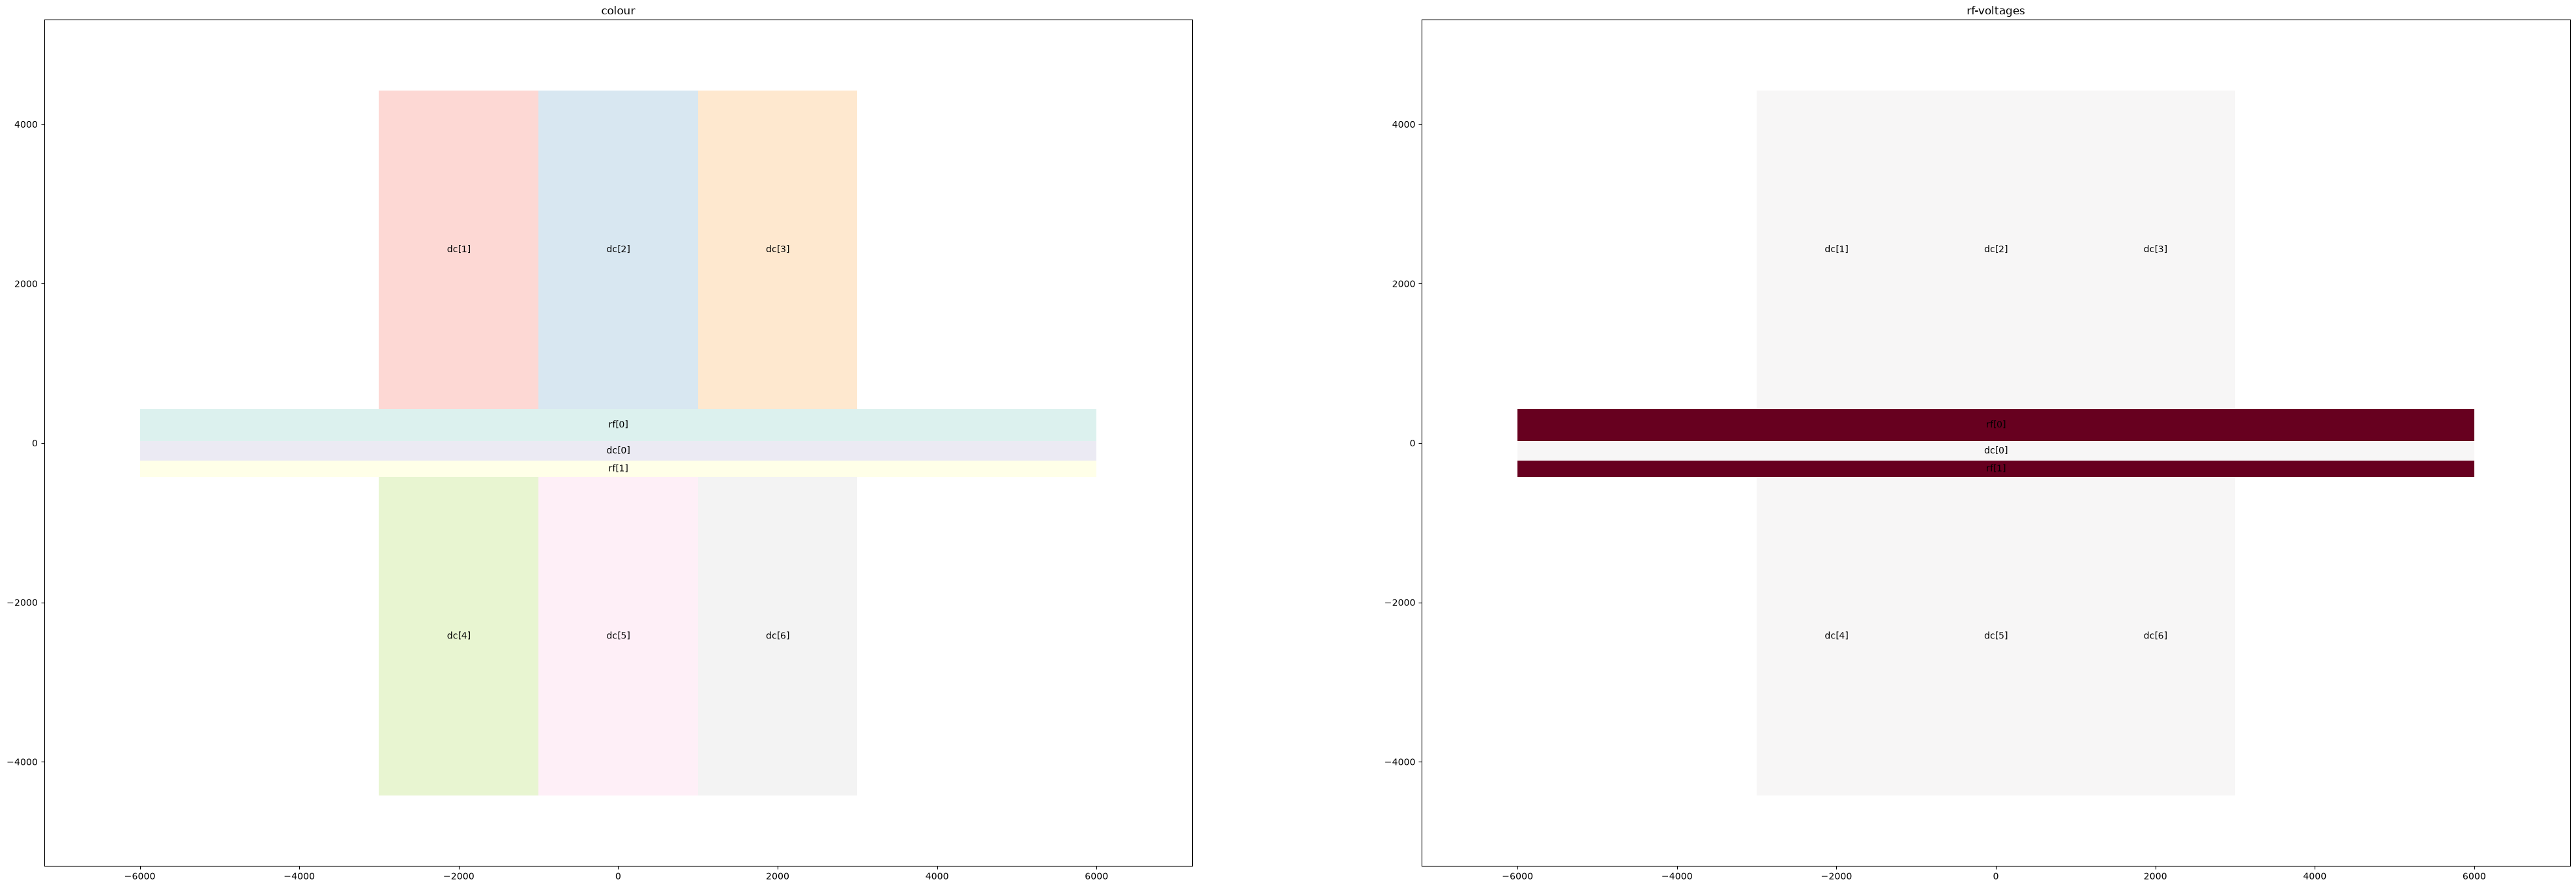

In [2]:
# Global definition of trap parameters. Used for all cells in this notebook
L = 1e-6 # µm length scale
Vrf = 500 # RF peak voltage in V
Omega = 2*np.pi*30e6 # RF frequency in rad/s
M = 40*ct.atomic_mass # ion mass
Z = 1*ct.elementary_charge # ion charge
# RF voltage in parametrized form so that the resulting potential equals the RF pseudopotential in eV
Urf = Vrf*np.sqrt(Z/M)/(2*L*Omega)


#parameters of trap
top_dc = [[2000, 4000]]*3
          
bottom_dc = top_dc #Array of lengths and widths of Bottom electrodes 
top_rf = [12000, 400]  #length of central dc, rf electrode
central_dc = [12000, 250]
bottom_rf =  [12000, 200]

gap = 0


s, RF_coordinates, DC_coordinates = sn.five_wire_trap_design(Urf, top_dc ,bottom_dc, top_rf, bottom_rf, central_dc, gap=gap,
                                                            need_coordinates = True, need_plot = True, figsize=(50,30))  #save_plot = 'linear_shuttling_trap.png'

## Potential characterization

The following block is used for potential characterisation to refine the potential for trapping of large ion crystals

Initial loss = 138.32807149931912


Optimizing voltages: 0it [00:00, ?it/s]

Optimizing voltages: 21it [00:00, 25.10it/s]

Final loss = 3.2870049342887677e-16
Final uset = [np.float64(-1.178298821453401), np.float64(6.428363553390092), np.float64(-8.191946445812013), np.float64(6.428896270281451), np.float64(9.987366465424614), np.float64(-3.6240813580921594), np.float64(9.987009723211981)]
For Calcium:
The minimum is (1.37e-08, -141, 217)
Distance from RF-minimum: (1.37e-08, -1.14e-08, -3.59e-09) um
Secular frequencies: (0.3113, 4.323, 4.364) MHz
In directions
a: [1.00000000e+00 6.64192799e-08 1.25119939e-08] 
b: [-6.75675163e-08  9.86926642e-01  1.61170105e-01] 
c: [-1.64361785e-09 -1.61170105e-01  9.86926642e-01]
Angle of secular modes rotation alpha: 0.16187614321554142
Mathieu frequencies: (0.3113, 4.48, 4.522) MHz


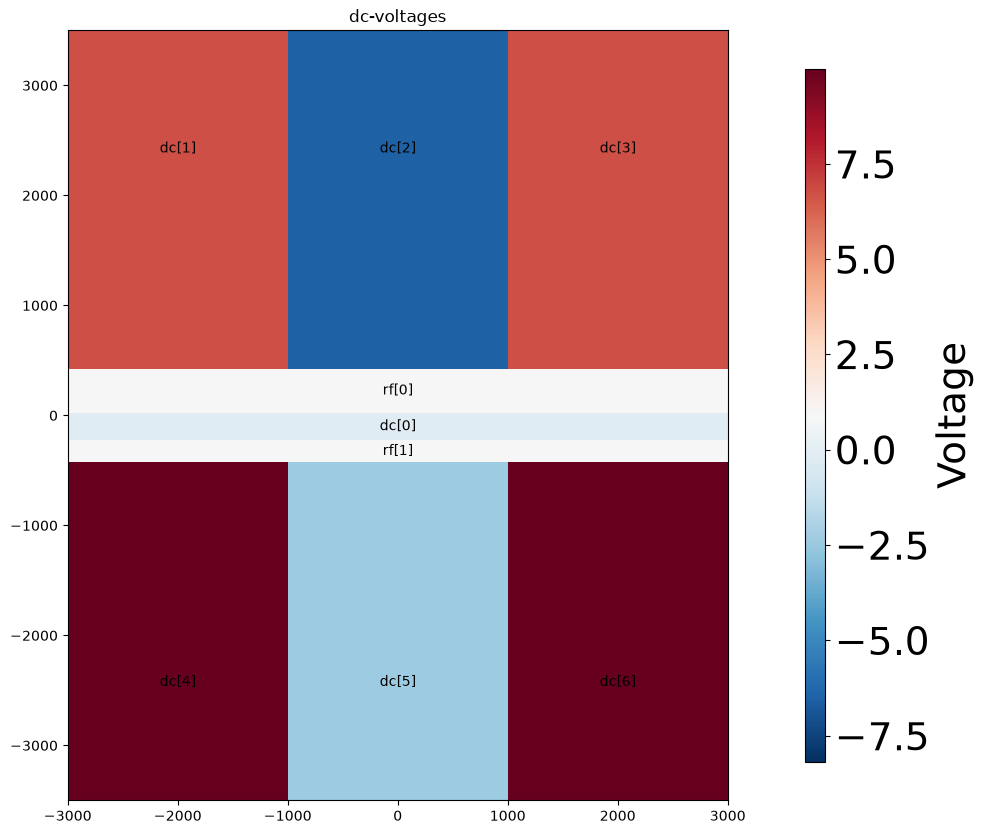

In [3]:
x0 = s.minimum([0,0,82.45], axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG", options={'maxiter': 1000000})
start_dc_set = np.array([-0.15, 6, -10, 6, 10, -6, 10])
u_set = np.append(np.zeros(2), start_dc_set)
rf_set = [Vrf, Vrf]
omegas = [Omega]*2

dc_set = sn.position_optimization(s, [[x0[0], x0[1], x0[2]]], start_dc_set, eps=1e-2, tol=1e-36, numbers=0, 
                          ion_masses=M, charges=1, callback_num=100, voltage_bounds=(-10,10))   #voltage search

u_set = np.append(np.zeros(2), dc_set)


with s.with_voltages(dcs = u_set, rfs = None):
    print('For Calcium:')
    x1 = s.minimum(x0*1.001, axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG")
    print('The minimum is (%.3g, %.3g, %.3g)' % (x1[0], x1[1], x1[2]))
    print('Distance from RF-minimum: (%.3g, %.3g, %.3g) um' % (x1[0] - x0[0], x1[1] - x0[1], x1[2] - x0[2]))
    # Get trap frequencies
    try:
        omega_sec, mod_dir = sn.single_ion_modes(s, x1, M)
        omega_sec *= 1e-6
        print("Secular frequencies: (%.4g, %.4g, %.4g) MHz" % (omega_sec[0],omega_sec[1],omega_sec[2]))
        print("In directions\na:", mod_dir[0],"\nb:", mod_dir[1],"\nc:", mod_dir[2] )
        e1 = np.array([0,0,1])
        alp = np.arccos(np.inner(mod_dir[2],e1))
        print('Angle of secular modes rotation alpha:', alp)
        
        omega_mathieu, mathieu_modes = sn.single_ion_modes(s, x1, M, mathieu=True, Omega=Omega)
        omega_mathieu *= 1e-6
        print("Mathieu frequencies: (%.4g, %.4g, %.4g) MHz" % (omega_mathieu[0],omega_mathieu[1],omega_mathieu[2]))
    except:
        print("Secular frequencies not found")

with s.with_voltages(dcs = u_set):    
    
    fig, ax = plt.subplots(1,1, figsize=(20, 10))
    s.plot_voltages(ax, u=s.dcs)
    #u = s.dcs sets the voltage-type for the voltage plot to DC-voltages (RF are not shown)
    xmax = 3000
    ymaxn = 3500
    ymaxp = 3500
    ax.set_title("dc-voltages")
    ax.set_aspect('equal')
    ax.set_xlim(-xmax, xmax)
    ax.set_ylim(-ymaxn, ymaxp)
    #Add colorbar
    cmap = plt.cm.RdBu_r
    norm = mpl.colors.Normalize(vmin=np.min(u_set), vmax=np.max(u_set))

    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink = 0.9, aspect = 35)
    
    """cb = plt.colorbar(ax=ax[2], shrink=0.9)"""
    cb.ax.tick_params(labelsize=28)
    cb.set_label('Voltage', fontsize = 28)


RF pseudopotential minimum: -0.9377 eV at (1.9e-08, -141, 217)µm
secular frequencies: (0.3113, 4.323, 4.364) MHz
in directions
a: [1.00000000e+00 6.64251249e-08 1.24945984e-08] 
b: [-6.75700050e-08  9.86973535e-01  1.60882693e-01] 
c: [-1.64518497e-09 -1.60882693e-01  9.86973535e-01]
Rotation angle = 0.162


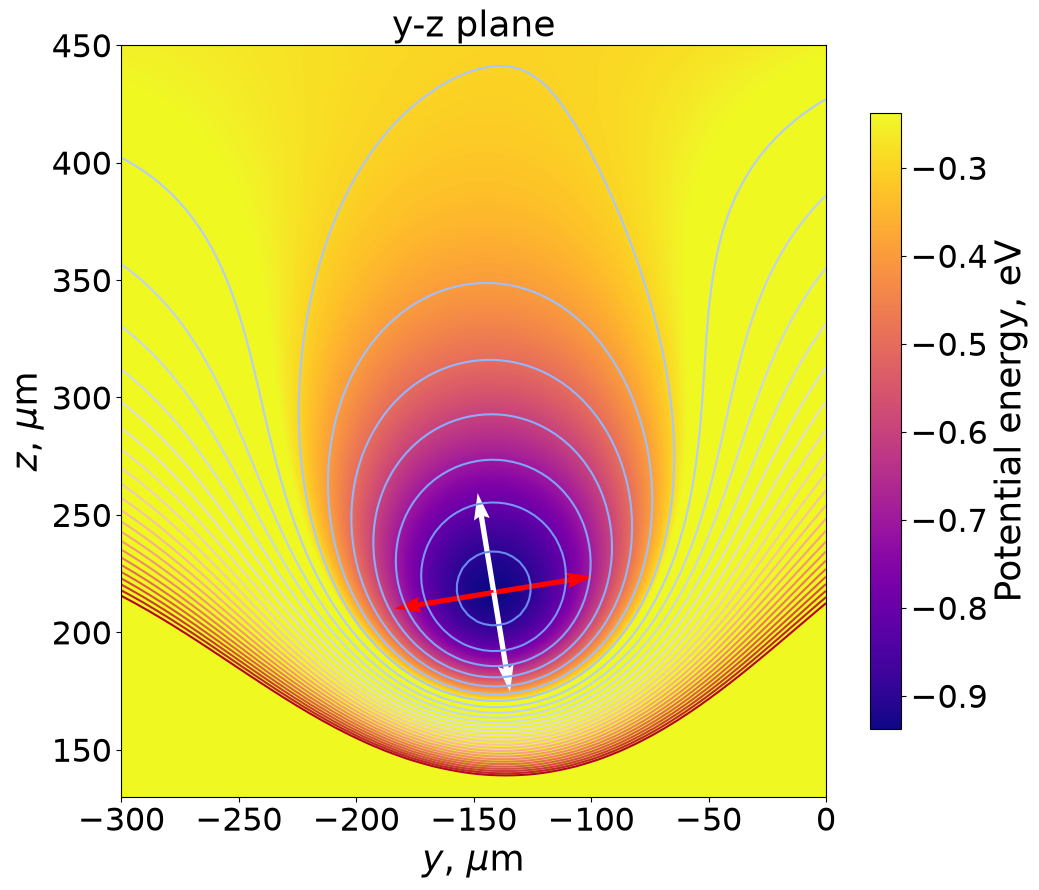

In [4]:
mass = M
with s.with_voltages(dcs = u_set, rfs = None):
#     try:81.
    x0 = s.minimum(x1*1.0001, axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG")
    p_tot0=s.potential(x0, 0)[0]
    print("RF pseudopotential minimum: %.4g" % p_tot0,"eV at (%.3g, %.3g, %.3g)µm" % (x0[0], x0[1], x0[2]))
#     except:
#         x0 = x_ini

    curv_z, mod_dir=s.modes(x0,sorted=False)
    omega_sec = np.sqrt(Z*curv_z/mass)/(2*np.pi)
    print("secular frequencies: (%.4g, %.4g, %.4g) MHz" % (omega_sec[0],omega_sec[1],omega_sec[2]))
    print("in directions\na:", mod_dir[0],"\nb:", mod_dir[1],"\nc:", mod_dir[2] )

    # 2D plot settings

    n=100 # resolution of meshgrid = resolution of 2D plots
    xmin, xmax = -1050, 900 #set the plot ranges
    ymin, ymax = -300, 0
    zmin, zmax = 130, 450
    x_cut, y_cut, z_cut = x0[0], x0[1], x0[2]# position of the yz-, xz-, xy- crossection
    v = np.arange(-1.4, 2., 0.1)# set the range for contour lines (range in eV)
    v_min, v_max = p_tot0, p_tot0 + 0.7  #set the range for colour map (range in eV)
    fs = 26 #set the fontsize
    ls = 23 #set the labelsize
    fig = plt.figure()
    fig.set_size_inches(25,10)

    # # y-z cross section
    ax3 = plt.subplot2grid((2,2), (0,1), rowspan=2)
    ax3.set_title("y-z plane" ,fontsize=fs)
    ax3.set_xlabel('$y$, $\\mu$m',fontsize=fs)
    ax3.set_ylabel('$z$, $\\mu$m',fontsize=fs)
    ax3.tick_params(axis='x', labelsize=ls)
    ax3.tick_params(axis='y', labelsize=ls)
    xyz = np.mgrid[x_cut:x_cut+1, ymin:ymax:1j*n, zmin:zmax:1j*n]
    pot = shaped(s.potential)(xyz)
    x, z, p = (_.reshape(n, n) for _ in (xyz[1], xyz[2], pot))
    CS=ax3.contour(x, z, p, v, cmap=plt.cm.coolwarm)
    im = ax3.imshow(p.T,cmap='plasma', origin='lower', vmin=v_min, vmax=v_max, extent=(ymin,ymax,zmin,zmax))
    im.set_interpolation('bilinear') 
    # ax3.set_yticks([60e-6, 80e-6, 100e-6, 120e-6, 140e-6], [60 ,80 ,100, 120, 140])
    # ax3.set_xticks([-60e-6, -40e-6, -20e-6, 0, 20e-6, 40e-6, 60e-6], [-60, -40, -20, 0, 20, 40, 60])
    # add colorbar
    cb = fig.colorbar(im, ax=ax3, shrink=0.8)
    cb.ax.tick_params(labelsize=ls)
    cb.set_label('Potential energy, eV', fontsize = fs)

    ax3.quiver(*[[x0[1]],[x0[2]]], mod_dir[1][1], mod_dir[1][2], color=['r'], scale = 7)
    ax3.quiver(*[[x0[1]],[x0[2]]], mod_dir[2][1], mod_dir[2][2], color=['w'], scale = 7)
    ax3.quiver(*[[x0[1]],[x0[2]]], -mod_dir[1][1], -mod_dir[1][2], color=['r'], scale = 7)
    ax3.quiver(*[[x0[1]],[x0[2]]], -mod_dir[2][1], -mod_dir[2][2], color=['w'], scale = 7)
    print(f'Rotation angle = {np.round(np.arccos(mod_dir[1][1]), 3)}')

## Electrode subdivision (single ion; fixed physical geometry)

Each of the six original side-DC electrodes is divided into `subdivision_factor` adjacent rectangles. Their lengths sum to the original length, their widths and positions follow the initial geometry, and each receives the same voltage as its parent electrode. For example, 3 side electrodes per side become 6, 12, or 24 per side with subdivision factors 2, 4, or 8. The central DC electrode and the two RF electrodes are unchanged.

Only side counts divisible by the original number of side electrodes are allowed. The helper returns the actual voltage array for the subdivided geometry in the expected SION electrode order.

In [5]:
BASE_SIDE_DC_COUNT = len(top_dc)


def benchmark_trap_initialization(side_dc_count, base_dc_voltages):
    """Create a same-voltage subdivision of the reference five-wire trap.

    Parameters
    ----------
    side_dc_count : int
        Number of DC rectangles *on each side* (not total electrodes).
        Must be a positive multiple of BASE_SIDE_DC_COUNT (=3 here).
    base_dc_voltages : array-like, length 1+2*BASE_SIDE_DC_COUNT
        Reference voltages in the original order: central DC, top DCs,
        bottom DCs. All subdivisions of a parent retain its voltage.

    Returns
    -------
    trap, rf_coordinates, dc_coordinates, scaled_dc_voltages
    """
    side_dc_count = int(side_dc_count)
    if side_dc_count < BASE_SIDE_DC_COUNT or side_dc_count % BASE_SIDE_DC_COUNT:
        raise ValueError(
            f"side_dc_count must be a multiple of {BASE_SIDE_DC_COUNT} "
            f"and at least {BASE_SIDE_DC_COUNT}; got {side_dc_count}."
        )
    if len(bottom_dc) != BASE_SIDE_DC_COUNT:
        raise ValueError("Reference top and bottom side counts must match.")

    base_dc_voltages = np.asarray(base_dc_voltages, dtype=float)
    expected = 1 + len(top_dc) + len(bottom_dc)
    if base_dc_voltages.shape != (expected,):
        raise ValueError(
            f"Expected {expected} reference DC voltages "
            f"(central + top + bottom), got {base_dc_voltages.shape}."
        )
    factor = side_dc_count // BASE_SIDE_DC_COUNT

    def subdivide(electrodes):
        return [
            [float(length) / factor, float(width)]
            for length, width in electrodes
            for _ in range(factor)
        ]

    expanded_top_dc = subdivide(top_dc)
    expanded_bottom_dc = subdivide(bottom_dc)
    scaled_dc_voltages = np.concatenate((
        base_dc_voltages[:1], np.repeat(base_dc_voltages[1:], factor)
    ))
    assert len(scaled_dc_voltages) == 1 + 2 * side_dc_count

    trap, rf_coordinates, dc_coordinates = sn.five_wire_trap_design(
        Urf, expanded_top_dc, expanded_bottom_dc, top_rf, bottom_rf,
        central_dc, gap=gap, need_coordinates=True, need_plot=False
    )
    return trap, rf_coordinates, dc_coordinates, scaled_dc_voltages

## Potential verification

This block verifies that the potential is the same in 3 points for different number of side DC electrodes in the benchmark strategy.

In [7]:
BASE_DC_VOLTAGES = np.asarray(dc_set, dtype=float).copy()  # from the reference calibration cell
CHECK_SIDE_COUNTS = [3, 6, 12, 24]
SAMPLE_POINTS_UM = np.array([
    [15.0, -130.0, 200.0],
    [0.0, -100.0, 180.0],
    [250.0, -150.0, 220.0],
], dtype=float)


def model_potential_at_points(model, scaled_voltages, points_um):
    with model.with_voltages(
        dcs=np.concatenate((np.zeros(2), scaled_voltages)), rfs=None
    ):
        return np.asarray([
            float(np.asarray(model.potential(point, 0)).reshape(-1)[0])
            for point in points_um
        ])


reference_trap, _, _, reference_voltages = benchmark_trap_initialization(
    BASE_SIDE_DC_COUNT, BASE_DC_VOLTAGES
)
reference_potentials = model_potential_at_points(
    reference_trap, reference_voltages, SAMPLE_POINTS_UM
)
for side_count in CHECK_SIDE_COUNTS:
    check_trap, _, _, check_voltages = benchmark_trap_initialization(
        side_count, BASE_DC_VOLTAGES
    )
    check_potentials = model_potential_at_points(
        check_trap, check_voltages, SAMPLE_POINTS_UM
    )
    max_abs_diff = np.max(np.abs(check_potentials - reference_potentials))
    print(f"{side_count:4d} side DC | {1 + 2*side_count:5d} total DC | "
          f"max |potential difference| = {max_abs_diff:.3e} (eV)")
    if max_abs_diff > 1e-6:
        print("   WARNING: check physical equivalence of these geometries "
              "before interpreting electrode-count scaling.")

   3 side DC |     7 total DC | max |potential difference| = 0.000e+00 (eV)
   6 side DC |    13 total DC | max |potential difference| = 1.776e-15 (eV)
  12 side DC |    25 total DC | max |potential difference| = 1.776e-15 (eV)
  24 side DC |    49 total DC | max |potential difference| = 1.332e-15 (eV)


## Polygon-trap simulation: benchmark definition

The one-ion simulation uses the **same initial position and the same RF/DC settings** for every electrode count. The timed interval is exactly `sim.execute()` and therefore includes process startup and file output, but excludes Python-side construction of the electrode model and simulation instructions.

In [12]:
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import subprocess
import sys
import traceback
from datetime import datetime, timezone

# Change BENCHMARK_ID if the geometry, voltages, MPI/OMP settings, dump policy,
# or the physical/numerical simulation parameters are changed.
BENCHMARK_ID = "electrode_scaling_dump1_v2"
bench_dir = output_dir / BENCHMARK_ID
cases_dir = bench_dir / "cases"
logs_dir = bench_dir / "simulations"
cases_dir.mkdir(parents=True, exist_ok=True)
logs_dir.mkdir(parents=True, exist_ok=True)

# Number of subdivided DC electrodes ON EACH SIDE. The baseline has 3 per side.
SIDE_DC_COUNTS = [3, 6, 12, 24, 48, 96, 192, 384, 768]
TOTAL_DC_COUNTS = [1 + 2 * n for n in SIDE_DC_COUNTS]
# To isolate electrode-number scaling on one MPI rank, use MPI_PROCESSES = [1].
# Other ranks are retained here for optional joint electrode/MPI scaling.
MPI_PROCESSES = [1, 4, 16, 40]
OMP_THREADS_BY_MPI = {p: [1] for p in MPI_PROCESSES}

SHORT_STEPS = 1
LONG_STEPS = 1001
STEPS = 1001         # Change to 1 to collect startup baselines; to 1001 for time-per-step calculation. rerun cells 12 onward.
REPEATS = 3
DUMP_EVERY = 1      
ORDER_SEED = 20261104
ION_POSITION_M = [15e-6, -130e-6, 200e-6]
ION_SPECIES = {"mass": 40, "charge": 1}
LANGEVIN_ARGS = (0, 5e-6)

if STEPS not in (SHORT_STEPS, LONG_STEPS):
    raise ValueError("Choose STEPS=1 or STEPS=1001 for the two-phase analysis.")
if not SIDE_DC_COUNTS or len(set(SIDE_DC_COUNTS)) != len(SIDE_DC_COUNTS):
    raise ValueError("SIDE_DC_COUNTS must contain distinct values.")
if any(n < BASE_SIDE_DC_COUNT or n % BASE_SIDE_DC_COUNT for n in SIDE_DC_COUNTS):
    raise ValueError(f"Each side count must be a multiple of {BASE_SIDE_DC_COUNT}.")
if any(not OMP_THREADS_BY_MPI.get(p) for p in MPI_PROCESSES):
    raise ValueError("Every MPI count needs at least one OpenMP-thread setting.")
if REPEATS < 1:
    raise ValueError("REPEATS must be >= 1.")

# Fixed reference voltages from the seven-electrode calibration above.
BASE_DC_VOLTAGES = np.asarray(dc_set, dtype=float).copy()
if BASE_DC_VOLTAGES.shape != (1 + 2 * BASE_SIDE_DC_COUNT,):
    raise ValueError("Reference calibration must return seven DC voltages.")


def _package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def _git_commit():
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=examples_dir,
            stderr=subprocess.DEVNULL, text=True, timeout=3,
        ).strip()
    except (OSError, subprocess.SubprocessError):
        return None


def case_tag(side_dc_count, mpi_processes, omp_threads, repeat, steps):
    total_dc = 1 + 2 * int(side_dc_count)
    return (f"sideDC{side_dc_count}_totalDC{total_dc}_mpi{mpi_processes}"
            f"_omp{omp_threads}_rep{repeat}_steps{steps}")


# Changes to any parameter below require a NEW BENCHMARK_ID. Only STEPS and
# REPEATS may vary between the two phases of the same experiment.
benchmark_config = {
    "side_dc_counts_per_side": SIDE_DC_COUNTS,
    "total_dc_counts": TOTAL_DC_COUNTS,
    "rf_electrode_count": 2,
    "ion_count": 1,
    "initial_ion_position_m": ION_POSITION_M,
    "ion_species": ION_SPECIES,
    "reference_dc_voltages_v": BASE_DC_VOLTAGES.tolist(),
    "reference_top_dc": top_dc,
    "reference_bottom_dc": bottom_dc,
    "top_rf": top_rf,
    "bottom_rf": bottom_rf,
    "central_dc": central_dc,
    "gap": gap,
    "rf_amplitude_v": Vrf,
    "rf_frequency_rad_per_s": Omega,
    "rf_pseudopotential_parameter": Urf,
    "omegas": omegas,
    "rf_voltage_set": rf_set,
    "langevin_args": list(LANGEVIN_ARGS),
    "mpi_processes": MPI_PROCESSES,
    "omp_threads_by_mpi": OMP_THREADS_BY_MPI,
    "dump_every": DUMP_EVERY,
    "dump_variables": ["x", "y", "z"],
    "step_phases": [SHORT_STEPS, LONG_STEPS],
}
config_sha256 = hashlib.sha256(
    json.dumps(benchmark_config, sort_keys=True).encode("utf-8")
).hexdigest()
metadata_file = bench_dir / "metadata.json"
metadata = {
    "protocol": "Single-ion, fixed-footprint, subdivided-DC-electrode scaling; sim.execute wall time with dump every step",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "benchmark_config": benchmark_config,
    "config_sha256": config_sha256,
    "machine": {
        "platform": platform.platform(),
        "processor": platform.processor(),
        "logical_cpus": os.cpu_count(),
        "python": sys.version,
    },
    "software": {
        "sion_distribution": _package_version("surface-ion"),
        "numpy": np.__version__,
        "scipy": _package_version("scipy"),
        "lammps_version": "RECORD FROM LAMMPS OUTPUT",
        "mpi_version": "RECORD FROM MPI ENVIRONMENT",
        "sion_git_commit": _git_commit(),
    },
    "notes": "Report physical CPU cores, processor model, and stable power settings. Dump I/O is included in every timed run.",
}
if metadata_file.exists():
    existing = json.loads(metadata_file.read_text(encoding="utf-8"))
    if existing.get("config_sha256") != config_sha256:
        raise ValueError(
            "BENCHMARK_ID already has different experiment settings. "
            "Use a NEW BENCHMARK_ID (do not merge incompatible runs)."
        )
    metadata = existing  # Preserve existing metadata and its first creation time.
else:
    metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")


def _atomic_json(path: Path, result: dict):
    """Save one case atomically, so interrupted sweeps remain restartable."""
    tmp = path.with_name(path.name + ".tmp")
    with tmp.open("w", encoding="utf-8") as file:
        json.dump(result, file, indent=2)
        file.flush()
        os.fsync(file.fileno())
    os.replace(tmp, path)


def simulation_benchmark(side_dc_count, mpi_processes, omp_threads=1,
                         repeat=0, steps=STEPS, dump_every=DUMP_EVERY):
    """Time simulation execution for one ion at a specified side-DC count."""
    tag = case_tag(side_dc_count, mpi_processes, omp_threads, repeat, steps)
    _, rf_coords, dc_coords, voltages = benchmark_trap_initialization(
        side_dc_count, BASE_DC_VOLTAGES
    )
    sim = pl.Simulation(str(logs_dir / tag))
    sim.append(pl.placeions(ION_SPECIES, [ION_POSITION_M]))
    sim.append(sn.polygon_trap(omegas, rf_set, voltages, rf_coords, dc_coords))
    sim.append(pl.langevinbath(*LANGEVIN_ARGS))
    if dump_every is not None:
        sim.append(pl.dump(
            str(logs_dir / f"dump_{tag}.txt"),
            variables=["x", "y", "z"], steps=int(dump_every)
        ))
    sim.append(pl.evolve(int(steps)))

    start = time.perf_counter()
    sim.execute(mpi_processes=int(mpi_processes), omp_threads=int(omp_threads))
    return time.perf_counter() - start


num_jobs = len(SIDE_DC_COUNTS) * sum(
    len(OMP_THREADS_BY_MPI[p]) for p in MPI_PROCESSES
) * REPEATS
print(f"Benchmark directory: {bench_dir}")
print(f"Step phase: {STEPS}; dump every {DUMP_EVERY} step(s); one ion per run.")
print(f"DC electrodes per side: {SIDE_DC_COUNTS}")
print(f"Total DC electrodes (plus 2 RF): {TOTAL_DC_COUNTS}")
print(f"MPI/OMP pairs: {[(p, t) for p in MPI_PROCESSES for t in OMP_THREADS_BY_MPI[p]]}")
print(f"Number of jobs in this phase: {num_jobs}")

Benchmark directory: c:\Users\User\Desktop\ARTEM\Sion\benchmark\supplementary\electrode_scaling_dump1_v2
Step phase: 1001; dump every 1 step(s); one ion per run.
DC electrodes per side: [3, 6, 12, 24, 48, 96, 192, 384, 768]
Total DC electrodes (plus 2 RF): [7, 13, 25, 49, 97, 193, 385, 769, 1537]
MPI/OMP pairs: [(1, 1), (4, 1), (16, 1), (40, 1)]
Number of jobs in this phase: 108


## Benchmarking process

A case is identified by **side DC count, total DC count, MPI ranks, OpenMP threads, repetition, and step count**. It is saved immediately to a separate JSON record, so completed cases are skipped on rerun.

If you change any physical configuration or the MPI/OMP settings, start a **new `BENCHMARK_ID`**. The metadata check prevents accidentally merging incompatible datasets.

In [13]:
jobs = [
    (side, mpi, omp, rep)
    for side in SIDE_DC_COUNTS
    for mpi in MPI_PROCESSES
    for omp in OMP_THREADS_BY_MPI[mpi]
    for rep in range(REPEATS)
]
random.Random(ORDER_SEED).shuffle(jobs)

completed = 0
for idx, (side, mpi, omp, rep) in enumerate(jobs, start=1):
    tag = case_tag(side, mpi, omp, rep, STEPS)
    record_path = cases_dir / f"{tag}.json"
    if record_path.exists():
        previous = json.loads(record_path.read_text(encoding="utf-8"))
        if previous.get("status") == "ok":
            completed += 1
            print(f"[{idx}/{len(jobs)}] SKIP {tag} "
                  f"({previous['execute_wall_s']:.3f} s)", flush=True)
            continue

    result = {
        "case": tag,
        "ion_count": 1,
        "side_dc_electrodes": side,
        "total_dc_electrodes": 1 + 2 * side,
        "total_electrodes_including_rf": 3 + 2 * side,
        "mpi_processes": mpi,
        "omp_threads": omp,
        "repeat": rep,
        "steps": STEPS,
        "dump_every": DUMP_EVERY,
        "started_utc": datetime.now(timezone.utc).isoformat(),
    }
    print(f"[{idx}/{len(jobs)}] RUN  {tag}", flush=True)
    try:
        wall_s = simulation_benchmark(
            side_dc_count=side, mpi_processes=mpi, omp_threads=omp,
            repeat=rep, steps=STEPS, dump_every=DUMP_EVERY,
        )
        result.update(
            status="ok", execute_wall_s=float(wall_s),
            amortized_wall_s_per_step=float(wall_s / STEPS),
        )
        completed += 1
        print(f"   DONE {wall_s:.3f} s "
              f"({wall_s / STEPS:.5g} s/amortized step)", flush=True)
    except Exception as exc:
        result.update(
            status="failed", error=repr(exc), traceback=traceback.format_exc()
        )
        print(f"   FAILED {type(exc).__name__}: {exc}", flush=True)
    finally:
        result["finished_utc"] = datetime.now(timezone.utc).isoformat()
        _atomic_json(record_path, result)

print(f"Successful cases: {completed}/{len(jobs)}. Records in: {cases_dir}")

[1/108] RUN  sideDC96_totalDC193_mpi40_omp1_rep2_steps1001
Reducing timestep to 2.652582384864922e-10 sec
[parallel] 40 MPI × 1 OMP
LAMMPS (30 Mar 2026)
  using 1 OpenMP thread(s) per MPI task
Loaded 0 plugins from C:\Users\User\AppData\Local\LAMMPS 64-bit 30Mar2026-MSMPI with Python\plugins
Created orthogonal box = (-0.01 -0.01 -0.01) to (0.01 0.01 0.01)
  2 by 4 by 5 MPI processor grid
Created 1 atoms.
  create_atoms CPU = 0.002 seconds
Setting atom values ...
  1 settings made for charge
1 atoms in group 1
1 atoms in group nonRigidBody
Generated 0 of 0 mixed pair_coeff terms from geometric mixing rule
Neighbor list info ...
  update: every = 1 steps, delay = 0 steps, check = yes
  max neighbors/atom: 2000, page size: 100000
  master list distance cutoff = 11
  ghost atom cutoff = 11
  1 neighbor lists, perpetual/occasional/extra = 1 0 0
  (1) pair coul/cut, perpetual
      attributes: half, newton on
      pair build: half/nsq/newton
      stencil: none
      bin: none
Setting up Ve

## Phase-specific analysis: execution time versus electrode count

This section summarizes **only the current `STEPS` phase**. The reported `t_wall_step_median` is `execute_wall_s / STEPS`, so it includes startup and per-step trajectory-file output. Use the final analysis cell to subtract the one-step baseline after collecting both phases.

In [14]:
import pandas as pd

records = [
    json.loads(path.read_text(encoding="utf-8"))
    for path in sorted(cases_dir.glob("*.json"))
]
grouped = pd.DataFrame()  # Clear stale results when re-running this notebook cell.
if not records:
    print("No benchmark results saved yet.")
else:
    raw = pd.DataFrame(records)
    ok = raw.loc[raw.status.eq("ok") & raw.steps.eq(STEPS)].copy()
    failed = raw.loc[raw.status.eq("failed") & raw.steps.eq(STEPS)]
    print(f"Current {STEPS}-step phase: successful={len(ok)}, failed={len(failed)}")
    if not ok.empty:
        ok.to_csv(bench_dir / f"results_steps{STEPS}.csv", index=False)
        grouping = ["side_dc_electrodes", "total_dc_electrodes",
                    "mpi_processes", "omp_threads"]
        grouped = (
            ok.groupby(grouping, as_index=False)
              .agg(
                  t_execute_median_s=("execute_wall_s", "median"),
                  t_wall_step_median=("amortized_wall_s_per_step", "median"),
                  t_wall_step_mean=("amortized_wall_s_per_step", "mean"),
                  t_wall_step_std=("amortized_wall_s_per_step", "std"),
                  repeats=("repeat", "count"),
              )
        )
        grouped["relative_std"] = (
            grouped.t_wall_step_std / grouped.t_wall_step_mean
        )
        baseline = (
            grouped.loc[
                grouped.mpi_processes.eq(1) & grouped.omp_threads.eq(1),
                ["side_dc_electrodes", "t_wall_step_median"]
            ].rename(columns={"t_wall_step_median": "baseline_s_per_step"})
        )
        grouped = grouped.merge(baseline, on="side_dc_electrodes", how="left")
        grouped["speedup"] = grouped.baseline_s_per_step / grouped.t_wall_step_median
        grouped["efficiency"] = (
            grouped.speedup / (grouped.mpi_processes * grouped.omp_threads)
        )
        display(grouped.sort_values(["side_dc_electrodes", "mpi_processes", "omp_threads"]))
        grouped.to_csv(bench_dir / f"summary_steps{STEPS}.csv", index=False)
        print("relative_std = standard deviation / mean across repeated runs; "
              "with 3 repeats, treat this as indicative rather than definitive.")

Current 1001-step phase: successful=108, failed=0


,side_dc_electrodes,total_dc_electrodes,mpi_processes,omp_threads,t_execute_median_s,t_wall_step_median,t_wall_step_mean,t_wall_step_std,repeats,relative_std,baseline_s_per_step,speedup,efficiency
0,3,7,1,1,5.263672,0.005258,0.005240,0.000053,3,0.010186,0.005258,1.000000,1.000000
1,3,7,4,1,6.358999,0.006353,0.006218,0.000256,3,0.041221,0.005258,0.827752,0.206938
2,3,7,16,1,7.464291,0.007457,0.007525,0.000127,3,0.016909,0.005258,0.705180,0.044074
3,3,7,40,1,15.139855,0.015125,0.014836,0.001240,3,0.083596,0.005258,0.347670,0.008692
4,6,13,1,1,8.518192,0.008510,0.008560,0.000183,3,0.021341,0.008510,1.000000,1.000000
5,6,13,4,1,10.893619,0.010883,0.010824,0.000213,3,0.019721,0.008510,0.781943,0.195486
6,6,13,16,1,13.718691,0.013705,0.013747,0.000183,3,0.013344,0.008510,0.620919,0.038807
7,6,13,40,1,24.991752,0.024967,0.024135,0.001900,3,0.078723,0.008510,0.340840,0.008521
8,12,25,1,1,15.331842,0.015317,0.015344,0.000187,3,0.012191,0.015317,1.000000,1.000000
9,12,25,4,1,19.736754,0.019717,0.019464,0.000678,3,0.034848,0.015317,0.776817,0.194204


relative_std = standard deviation / mean across repeated runs; with 3 repeats, treat this as indicative rather than definitive.


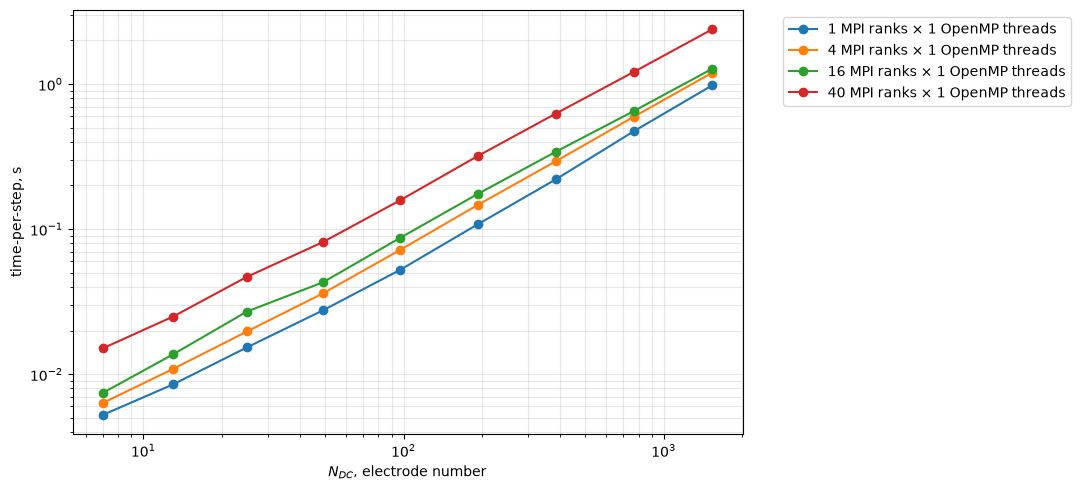

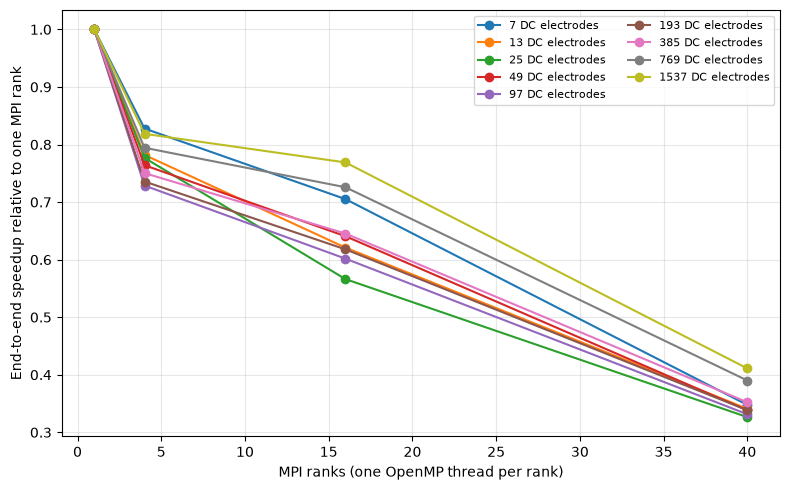

Fastest measured process configuration at each DC electrode count:


,side_dc_electrodes,total_dc_electrodes,mpi_processes,omp_threads,t_wall_step_median
0,3,7,1,1,0.005258
4,6,13,1,1,0.008510
8,12,25,1,1,0.015317
12,24,49,1,1,0.027572
16,48,97,1,1,0.052405
20,96,193,1,1,0.108141
24,192,385,1,1,0.220558
28,384,769,1,1,0.473842
32,768,1537,1,1,0.980477


In [18]:
if not grouped.empty:
    fig, ax = plt.subplots(figsize=(11, 5))
    for (mpi, omp), frame in grouped.groupby(["mpi_processes", "omp_threads"]):
        frame = frame.sort_values("total_dc_electrodes")
        ax.loglog(frame.total_dc_electrodes, frame.t_wall_step_median, "o-",
                  label=f"{mpi} MPI ranks × {omp} OpenMP threads")
    ax.set_xlabel(r"$N_{DC}$, electrode number")
    ax.set_ylabel("time-per-step, s")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    fig.tight_layout()
    fig.savefig(bench_dir / f"electrodes_wall_time_per_step_steps{STEPS}.png", dpi=220)
    plt.show()

    if len(MPI_PROCESSES) > 1:
        fig, ax = plt.subplots(figsize=(8, 5))
        for total_dc, frame in grouped.groupby("total_dc_electrodes"):
            frame = frame.loc[frame.omp_threads.eq(1)].sort_values("mpi_processes")
            if frame.speedup.notna().any():
                ax.plot(frame.mpi_processes, frame.speedup, "o-",
                        label=f"{total_dc} DC electrodes")
        ax.set_xlabel("MPI ranks (one OpenMP thread per rank)")
        ax.set_ylabel("End-to-end speedup relative to one MPI rank")
        ax.grid(True, alpha=0.3)
        ax.legend(ncol=2, fontsize=8)
        fig.tight_layout()
        fig.savefig(bench_dir / f"electrodes_mpi_speedup_steps{STEPS}.png", dpi=220)
        plt.show()

    best = grouped.loc[
        grouped.groupby("total_dc_electrodes").t_wall_step_median.idxmin(),
        ["side_dc_electrodes", "total_dc_electrodes", "mpi_processes",
         "omp_threads", "t_wall_step_median"]
    ]
    print("Fastest measured process configuration at each DC electrode count:")
    display(best.sort_values("total_dc_electrodes"))

## Extracting time-per-step metric

Here we substract mean execution times for 1001 and 1 step simulations, to get practical time-per-step metric.

,side_dc_electrodes,total_dc_electrodes,mpi_processes,omp_threads,median_1step_s,median_1001steps_s,incremental_s_per_step,paired_median_s_per_step,paired_std_s_per_step,paired_repeats
0,3,7,1,1,0.320013,5.263672,0.004944,0.004944,0.000024,3
1,3,7,4,1,0.394280,6.358999,0.005965,0.005978,0.000273,3
2,3,7,16,1,0.589647,7.464291,0.006875,0.006865,0.000146,3
3,3,7,40,1,1.116798,15.139855,0.014023,0.014038,0.001222,3
4,6,13,1,1,0.315538,8.518192,0.008203,0.008244,0.000157,3
5,6,13,4,1,0.447848,10.893619,0.010446,0.010474,0.000210,3
6,6,13,16,1,0.628102,13.718691,0.013091,0.013057,0.000224,3
7,6,13,40,1,1.096872,24.991752,0.023895,0.023104,0.001782,3
8,12,25,1,1,0.397608,15.331842,0.014934,0.014958,0.000176,3
9,12,25,4,1,0.448674,19.736754,0.019288,0.019255,0.000683,3


Paired configurations: 36 of 36 measured configurations


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


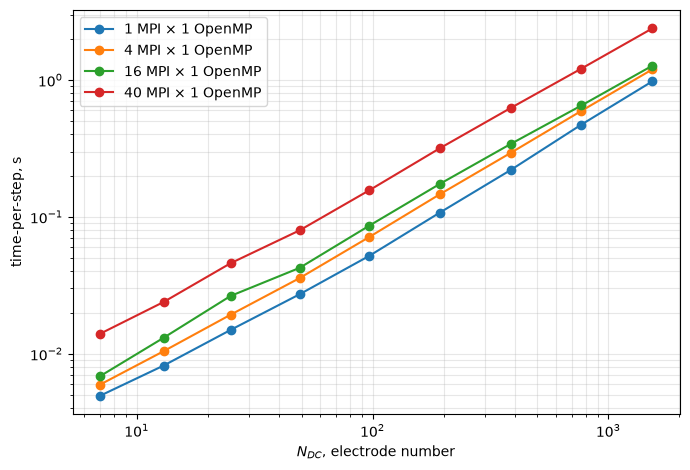

In [22]:
records = [
    json.loads(path.read_text(encoding="utf-8"))
    for path in sorted(cases_dir.glob("*.json"))
]
net = pd.DataFrame()
paired = pd.DataFrame()
if not records:
    print("No timing records yet.")
else:
    all_records = pd.DataFrame(records)
    all_ok = all_records.loc[
        all_records.status.eq("ok") &
        all_records.steps.isin([SHORT_STEPS, LONG_STEPS])
    ].copy()
    if all_ok.empty:
        print("No successful 1-step or 1001-step records yet.")
    else:
        config_cols = [
            "side_dc_electrodes", "total_dc_electrodes",
            "mpi_processes", "omp_threads"
        ]
        phases = (
            all_ok.groupby(config_cols + ["steps"])
                  .execute_wall_s.median()
                  .unstack("steps")
        )
        if {SHORT_STEPS, LONG_STEPS}.issubset(phases.columns):
            net = phases.dropna(subset=[SHORT_STEPS, LONG_STEPS]).copy()
            net = net.rename(columns={
                SHORT_STEPS: "median_1step_s",
                LONG_STEPS: "median_1001steps_s",
            })
            net["incremental_s_per_step"] = (
                (net.median_1001steps_s - net.median_1step_s) /
                (LONG_STEPS - SHORT_STEPS)
            )
            net = net.reset_index().sort_values(config_cols)

            # Matched replicate numbers give a dispersion estimate for the
            # startup-subtracted cost; they are independent executions.
            paired = all_ok.pivot_table(
                index=config_cols + ["repeat"], columns="steps",
                values="execute_wall_s", aggfunc="first"
            )
            paired = paired.dropna(subset=[SHORT_STEPS, LONG_STEPS]).copy()
            paired["incremental_s_per_step"] = (
                (paired[LONG_STEPS] - paired[SHORT_STEPS]) /
                (LONG_STEPS - SHORT_STEPS)
            )
            pair_stats = (
                paired.reset_index().groupby(config_cols, as_index=False)
                    .agg(
                        paired_median_s_per_step=("incremental_s_per_step", "median"),
                        paired_std_s_per_step=("incremental_s_per_step", "std"),
                        paired_repeats=("repeat", "count"),
                    )
            )
            net = net.merge(pair_stats, on=config_cols, how="left")
            if (net.incremental_s_per_step <= 0).any():
                print("WARNING: some startup-subtracted estimates are nonpositive; "
                      "inspect timing variability and increase run length if needed.")
            display(net)
            net.to_csv(bench_dir / "electrodes_incremental_per_step.csv", index=False)
            paired.reset_index().to_csv(
                bench_dir / "electrodes_paired_phase_runs.csv", index=False
            )
            print(f"Paired configurations: {len(net)} "
                  f"of {len(phases)} measured configurations")

            fig, ax = plt.subplots(figsize=(7, 4.8))
            for (mpi, omp), frame in net.groupby(["mpi_processes", "omp_threads"]):
                frame = frame.sort_values("total_dc_electrodes")
                valid = frame.loc[frame.incremental_s_per_step.gt(0)]
                if valid.empty:
                    continue
                ax.loglog(valid.total_dc_electrodes,
                          valid.incremental_s_per_step, "o-",
                          label=f"{mpi} MPI × {omp} OpenMP")
            ax.set_xlabel(r"$N_{DC}$, electrode number")
            ax.set_ylabel("time-per-step, s")
            ax.grid(True, which="both", alpha=0.3)
            ax.legend(loc="upper left")
            fig.tight_layout()
            fig.savefig(bench_dir / "electrodes_number_scaling.eps")
            plt.show()
        else:
            present = sorted(phases.columns.tolist())
            print(f"Both {SHORT_STEPS}- and {LONG_STEPS}-step phases are needed "
                  f"for subtraction. Available phases: {present}.")